In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, regularizers, Sequential
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. Configuration
DATA_DIR = "data/flower_photos"
IMG_SIZE = (64, 64)
BATCH_SIZE = 32
EPOCHS = 50
SEED = 42

In [3]:
# 2. Load dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [4]:
# 3. Improve data loading
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

In [5]:
# 4. Build ANN (no CNN layers)
model = Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Normalize pixel values
    layers.Rescaling(1.0 / 255),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    # Flatten image into a vector
    layers.Flatten(),

    # Hidden layer 1: L2 regularization
    layers.Dense(
        256,
        kernel_regularizer=regularizers.l2(0.001),
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),

    # Hidden layer 2: L1 + L2 regularization
    layers.Dense(
        128,
        kernel_regularizer=regularizers.l1_l2(
            l1=0.0001,
            l2=0.001
        ),
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.4),

    # Output layer
    layers.Dense(num_classes, activation="softmax")
])


In [6]:
# 5. Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,145,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,180,677 (12.13 MB)

 Trainable params: 3,179,909 (12.13 MB)

 Non-trainable params: 768 (3.00 KB)

In [7]:
# 6. Callbacks
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_flower_ann.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [8]:
# 7. Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/50


c:\Users\windows\Desktop\projects\computer-vision\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.3770 - loss: 2.4952
Epoch 1: val_loss improved from None to 2.42681, saving model to best_flower_ann.keras

Epoch 1: finished saving model to best_flower_ann.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - accuracy: 0.3770 - loss: 2.4952 - val_accuracy: 0.3338 - val_loss: 2.4268
Epoch 2/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.4240 - loss: 2.2320
Epoch 2: val_loss improved from 2.42681 to 2.24588, saving model to best_flower_ann.keras

Epoch 2: finished saving model to best_flower_ann.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 62ms/step - accuracy: 0.4240 - loss: 2.2320 - val_accuracy: 0.3692 - val_loss: 2.2459
Epoch 3/50
91/92 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.4375 - loss: 2.0995
Epoch 3: val_loss improved from 2.24588 to 2.02613, saving model to best_flower_ann.keras

Epoch 3: finished saving model to best_flower_ann.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.4377 - loss: 2.0983 - val_accura

In [9]:
# 8. Evaluate
val_loss, val_accuracy = model.evaluate(val_ds)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.2%}")


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3760 - loss: 1.5984
Validation loss: 1.5984
Validation accuracy: 37.60%


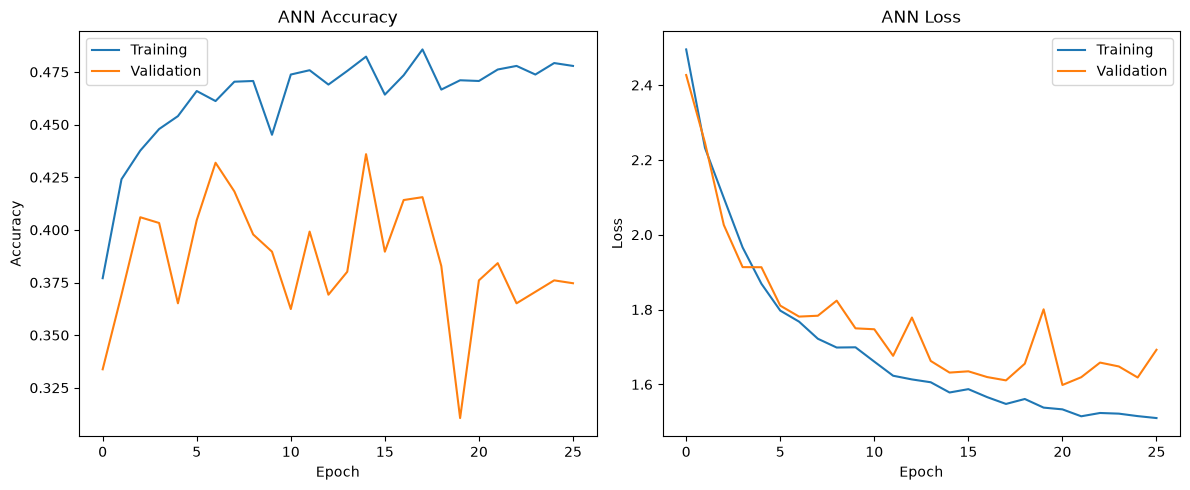

In [10]:
# 9. Plot training history
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("ANN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


Technique	What it does in your model

Input rescaling	Scales pixel values to 0–1

Data augmentation	Creates variations of training images

Flatten	Converts the image into a 12,288-value vector

L1/L2 regularization	Adds penalties to discourage unnecessarily large or numerous weights

Batch Normalization	Normalizes intermediate layer activations

ReLU	Introduces non-linearity

Dropout	Randomly disables activations during training

Adam	Updates weights during optimization

Early Stopping	Stops training when validation loss stops improving

Model Checkpoint	Saves the best validation-loss model